# 06 – Model Evaluation, Customer Segment Interpretation and Business Recommendations

## 1. Introduction

This notebook focuses on the evaluation and interpretation of the customer segmentation models developed in the previous modelling phase.

The objective is to identify the most appropriate customer segmentation solution by considering internal validation metrics, cluster stability, customer profile differentiation and practical interpretability.

The analysis will build on the RFM and extended-feature clustering experiments conducted using K-Means and Agglomerative Hierarchical Clustering.

## 2. Objectives

1. Evaluate and compare the candidate segmentation solutions.
2. Select and justify the most appropriate final clustering model.
3. Develop detailed profiles of the identified customer segments.
4. Examine the geographic distribution of customers across segments.
5. Translate customer profiles into commercially meaningful insights.
6. Develop practical customer engagement and retention recommendations.
7. Discuss the limitations and responsible use of the segmentation results.

## 3. Analytical approach

The evaluation will consider:

- Silhouette Score
- Davies–Bouldin Index
- Calinski–Harabasz Index
- Cluster sizes and proportions
- Customer-level behavioural profiles
- Stability and sensitivity findings
- Business interpretability

The final model will be selected based on a combination of statistical evidence and practical usefulness rather than a single evaluation metric.

## 4. Scope

The analysis will use the processed customer-level datasets and clustering results generated in the previous notebooks.

CustomerID will be retained only for customer identification and aggregation. Country will be used for supplementary cluster profiling and will not be included as a primary clustering feature.

No causal claims will be made from the resulting customer segments.

# Section 6.1 – Import libraries and verify Phase 6 inputs

In [1]:

# Section 6.1 – Import libraries and verify Phase 6 inputs

import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

# Define processed data directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

required_files = [
    "original_customer_features.csv",
    "original_rfm_standard_scaled.csv",
    "original_extended_standard_scaled.csv",
    "original_reduced_extended_standard_scaled.csv"
]

print("PHASE 6 INPUT VERIFICATION")
print("--------------------------------")

for filename in required_files:
    file_path = PROCESSED_DIR / filename

    print(f"\n{filename}")
    print("Available:", file_path.exists())

    if file_path.exists():
        temp_df = pd.read_csv(file_path)
        print("Shape:", temp_df.shape)
        print("Missing values:", temp_df.isnull().sum().sum())

print("\nProcessed data directory:", PROCESSED_DIR)


PHASE 6 INPUT VERIFICATION
--------------------------------

original_customer_features.csv
Available: True
Shape: (4335, 9)
Missing values: 1505

original_rfm_standard_scaled.csv
Available: True
Shape: (4335, 4)
Missing values: 0

original_extended_standard_scaled.csv
Available: True
Shape: (4335, 7)
Missing values: 0

original_reduced_extended_standard_scaled.csv
Available: True
Shape: (4335, 6)
Missing values: 0

Processed data directory: c:\Users\yadav\OneDrive\Desktop\Online_Retail_Customer_Segmentation\data\processed


### Section 6.2 — Inspect customer-level data

In [2]:
# Load the original customer-level features

customer_features = pd.read_csv(
    PROCESSED_DIR / "original_customer_features.csv"
)

print("CUSTOMER FEATURE DATASET")
print("--------------------------------")

print("Shape:", customer_features.shape)

print("\nColumns:")
print(customer_features.columns.tolist())

print("\nMissing values by column:")
print(
    customer_features.isnull()
    .sum()
    .sort_values(ascending=False)
)

print("\nData types:")
print(customer_features.dtypes)

print("\nUnique customer IDs:")
print(customer_features["CustomerID"].nunique())

print("\nDuplicate customer IDs:")
print(customer_features["CustomerID"].duplicated().sum())

print("\nSample records:")
display(customer_features.head())

CUSTOMER FEATURE DATASET
--------------------------------
Shape: (4335, 9)

Columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'LastPurchaseDate', 'AverageOrderValue', 'TotalQuantity', 'ProductDiversity', 'PurchaseRegularity']

Missing values by column:
PurchaseRegularity    1505
CustomerID               0
Recency                  0
Monetary                 0
Frequency                0
LastPurchaseDate         0
AverageOrderValue        0
TotalQuantity            0
ProductDiversity         0
dtype: int64

Data types:
CustomerID            float64
Recency                 int64
Frequency               int64
Monetary              float64
LastPurchaseDate          str
AverageOrderValue     float64
TotalQuantity           int64
ProductDiversity        int64
PurchaseRegularity    float64
dtype: object

Unique customer IDs:
4335

Duplicate customer IDs:
0

Sample records:


,CustomerID,Recency,Frequency,Monetary,LastPurchaseDate,AverageOrderValue,TotalQuantity,ProductDiversity,PurchaseRegularity
0,12346.0,326,1,77183.60,2011-01-18 10:01:00,77183.600000,74215,1,NaN
1,12347.0,3,7,4310.00,2011-12-07 15:52:00,615.714286,2458,103,60.839699
2,12348.0,76,4,1437.24,2011-09-25 13:13:00,359.310000,2332,21,94.250926
3,12349.0,19,1,1457.55,2011-11-21 09:51:00,1457.550000,630,72,NaN
4,12350.0,311,1,294.40,2011-02-02 16:01:00,294.400000,196,16,NaN


In [3]:
# Check whether missing PurchaseRegularity is associated with single-invoice customers

print("PURCHASE REGULARITY MISSINGNESS CHECK")
print("--------------------------------")

missing_regularity = customer_features[
    customer_features["PurchaseRegularity"].isna()
]

available_regularity = customer_features[
    customer_features["PurchaseRegularity"].notna()
]

print("Customers with missing PurchaseRegularity:",
      len(missing_regularity))

print("Customers with available PurchaseRegularity:",
      len(available_regularity))

print("\nFrequency distribution among customers with missing values:")
display(missing_regularity["Frequency"].value_counts().sort_index())

print("\nFrequency distribution among customers with available values:")
display(available_regularity["Frequency"].value_counts().sort_index())

print("\nMissing PurchaseRegularity among customers with Frequency > 1:",
      customer_features.loc[
          customer_features["Frequency"] > 1,
          "PurchaseRegularity"
      ].isna().sum())

print("\nMissing PurchaseRegularity among customers with Frequency = 1:",
      customer_features.loc[
          customer_features["Frequency"] == 1,
          "PurchaseRegularity"
      ].isna().sum())

PURCHASE REGULARITY MISSINGNESS CHECK
--------------------------------
Customers with missing PurchaseRegularity: 1505
Customers with available PurchaseRegularity: 2830

Frequency distribution among customers with missing values:


Frequency
1    1505
Name: count, dtype: int64


Frequency distribution among customers with available values:


Frequency
2      830
3      504
4      394
5      237
6      173
7      138
8       98
9       69
10      55
11      54
12      43
13      29
14      19
15      26
16      10
17      19
18      13
19      12
20      13
21      10
22       6
23       4
24       3
25       8
26       7
27       4
28       6
29       1
30       3
31       4
32       2
33       2
34       3
35       1
36       1
37       4
39       2
41       1
44       2
46       1
47       2
48       1
50       1
51       1
55       2
57       1
60       1
62       2
72       1
86       1
91       2
97       1
124      1
199      1
206      1
Name: count, dtype: int64


Missing PurchaseRegularity among customers with Frequency > 1: 0

Missing PurchaseRegularity among customers with Frequency = 1: 1505


### Section 6.3 – Load and verify modelling datasets

In [ ]:
# Section 6.3 – Load and verify modelling datasets

rfm_scaled = pd.read_csv(
    PROCESSED_DIR / "original_rfm_standard_scaled.csv"
)

extended_scaled = pd.read_csv(
    PROCESSED_DIR / "original_extended_standard_scaled.csv"
)

reduced_extended_scaled = pd.read_csv(
    PROCESSED_DIR / "original_reduced_extended_standard_scaled.csv"
)

print("MODELLING DATASET VERIFICATION")
print("--------------------------------")

datasets = {
    "RFM": rfm_scaled,
    "Extended": extended_scaled,
    "Reduced Extended": reduced_extended_scaled
}

for name, data in datasets.items():
    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Unique customers:", data["CustomerID"].nunique())
    print("Duplicate CustomerIDs:", data["CustomerID"].duplicated().sum())
    print("Missing values:", data.isnull().sum().sum())

# Verify that all modelling datasets contain the same customers
same_customers = (
    set(rfm_scaled["CustomerID"])
    == set(extended_scaled["CustomerID"])
    == set(reduced_extended_scaled["CustomerID"])
)

print("\nDo all three datasets contain the same customers?", same_customers)

MODELLING DATASET VERIFICATION
--------------------------------

RFM
Shape: (4335, 4)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Extended
Shape: (4335, 7)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'TotalQuantity', 'ProductDiversity']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Reduced Extended
Shape: (4335, 6)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AverageOrderValue', 'ProductDiversity']
Unique customers: 4335
Duplicate CustomerIDs: 0
Missing values: 0

Do all three datasets contain the same customers? True


### Section 6.2 – Recalculate evaluation metrics for final model candidates

In [5]:
# Section 6.2 – Recalculate evaluation metrics for final model candidates

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Prepare feature matrices by excluding CustomerID
X_rfm = rfm_scaled.drop(columns=["CustomerID"])

X_extended = extended_scaled.drop(columns=["CustomerID"])

X_reduced_extended = reduced_extended_scaled.drop(
    columns=["CustomerID"]
)

# Define candidate models
candidate_models = {
    "RFM | K-Means | K=3": (
        X_rfm,
        KMeans(n_clusters=3, random_state=42, n_init=20)
    ),

    "RFM | Hierarchical | K=2": (
        X_rfm,
        AgglomerativeClustering(n_clusters=2, linkage="ward")
    ),

    "RFM | Hierarchical | K=3": (
        X_rfm,
        AgglomerativeClustering(n_clusters=3, linkage="ward")
    ),

    "Extended | K-Means | K=2": (
        X_extended,
        KMeans(n_clusters=2, random_state=42, n_init=20)
    ),

    "Extended | Hierarchical | K=2": (
        X_extended,
        AgglomerativeClustering(n_clusters=2, linkage="ward")
    ),

    "Reduced Extended | K-Means | K=2": (
        X_reduced_extended,
        KMeans(n_clusters=2, random_state=42, n_init=20)
    )
}

# Fit models and calculate evaluation metrics
final_model_results = []
final_model_labels = {}

for model_name, (X, model) in candidate_models.items():

    labels = model.fit_predict(X)

    final_model_labels[model_name] = labels

    final_model_results.append({
        "Model": model_name,
        "Number_of_Clusters": len(np.unique(labels)),
        "Silhouette_Score": silhouette_score(X, labels),
        "Davies_Bouldin_Index": davies_bouldin_score(X, labels),
        "Calinski_Harabasz_Index": calinski_harabasz_score(X, labels)
    })

# Create comparison table
final_model_comparison = pd.DataFrame(final_model_results)

final_model_comparison = final_model_comparison.sort_values(
    by="Silhouette_Score",
    ascending=False
).reset_index(drop=True)

print("FINAL CANDIDATE MODEL COMPARISON")
print("--------------------------------")

display(
    final_model_comparison.round(4)
)

FINAL CANDIDATE MODEL COMPARISON
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206
1,RFM | Hierarchical | K=2,2,0.3965,0.8371,3276.0686
2,RFM | Hierarchical | K=3,3,0.3956,0.8669,4151.0791
3,Extended | K-Means | K=2,2,0.3511,1.0616,3116.7941
4,Reduced Extended | K-Means | K=2,2,0.3360,1.1176,2802.5822
5,Extended | Hierarchical | K=2,2,0.3237,1.0306,2510.9298


### Section 6.3 – Final candidate model: RFM K-Means (K=3) cluster profiling

In [6]:
# Section 6.3 – Final candidate model: RFM K-Means (K=3) cluster profiling

# Retrieve cluster labels from the fitted model
rfm_kmeans_labels = final_model_labels["RFM | K-Means | K=3"]

# Create a customer-level profiling dataset
rfm_profile_data = customer_features.copy()

rfm_profile_data["Cluster"] = rfm_kmeans_labels

# Calculate cluster sizes
cluster_sizes = (
    rfm_profile_data["Cluster"]
    .value_counts()
    .sort_index()
    .rename("Customer_Count")
    .to_frame()
)

cluster_sizes["Customer_Percentage"] = (
    cluster_sizes["Customer_Count"]
    / len(rfm_profile_data)
    * 100
)

print("RFM K-MEANS (K=3): CLUSTER SIZES")
print("--------------------------------")

display(cluster_sizes.round(2))

# Calculate mean profiles
profile_variables = [
    "Recency",
    "Frequency",
    "Monetary"
]

cluster_means = (
    rfm_profile_data
    .groupby("Cluster")[profile_variables]
    .mean()
    .round(2)
)

print("\nCLUSTER PROFILES – MEAN VALUES")
print("--------------------------------")

display(cluster_means)

# Calculate median profiles
cluster_medians = (
    rfm_profile_data
    .groupby("Cluster")[profile_variables]
    .median()
    .round(2)
)

print("\nCLUSTER PROFILES – MEDIAN VALUES")
print("--------------------------------")

display(cluster_medians)

RFM K-MEANS (K=3): CLUSTER SIZES
--------------------------------


,Customer_Count,Customer_Percentage
Cluster,,
0,2025,46.71
1,1325,30.57
2,985,22.72



CLUSTER PROFILES – MEAN VALUES
--------------------------------


,Recency,Frequency,Monetary
Cluster,,,
0,55.23,2.03,604.45
1,30.54,9.76,5374.77
2,255.70,1.39,404.57



CLUSTER PROFILES – MEDIAN VALUES
--------------------------------


,Recency,Frequency,Monetary
Cluster,,,
0,46.0,2.0,501.28
1,18.0,7.0,2504.13
2,253.0,1.0,290.34


### Section 6.3 – Extended behavioural profiling of RFM clusters

In [7]:
# Section 6.3 – Extended behavioural profiling of RFM clusters

extended_profile_variables = [
    "AverageOrderValue",
    "TotalQuantity",
    "ProductDiversity"
]

# Add the RFM cluster labels to the customer-level dataset
extended_profile_data = customer_features.copy()

extended_profile_data["Cluster"] = rfm_kmeans_labels

# Calculate median behavioural profiles
extended_medians = (
    extended_profile_data
    .groupby("Cluster")[extended_profile_variables]
    .median()
    .round(2)
)

print("EXTENDED BEHAVIOURAL PROFILES – MEDIAN VALUES")
print("--------------------------------")

display(extended_medians)

# Calculate mean behavioural profiles
extended_means = (
    extended_profile_data
    .groupby("Cluster")[extended_profile_variables]
    .mean()
    .round(2)
)

print("\nEXTENDED BEHAVIOURAL PROFILES – MEAN VALUES")
print("--------------------------------")

display(extended_means)

EXTENDED BEHAVIOURAL PROFILES – MEDIAN VALUES
--------------------------------


,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,
0,255.40,284.0,29.0
1,360.23,1496.0,95.0
2,216.76,140.0,16.0



EXTENDED BEHAVIOURAL PROFILES – MEAN VALUES
--------------------------------


,AverageOrderValue,TotalQuantity,ProductDiversity
Cluster,,,
0,335.92,385.00,39.08
1,620.00,3120.53,124.61
2,303.91,231.08,22.36


### Section 6.4 – Customer segment distribution

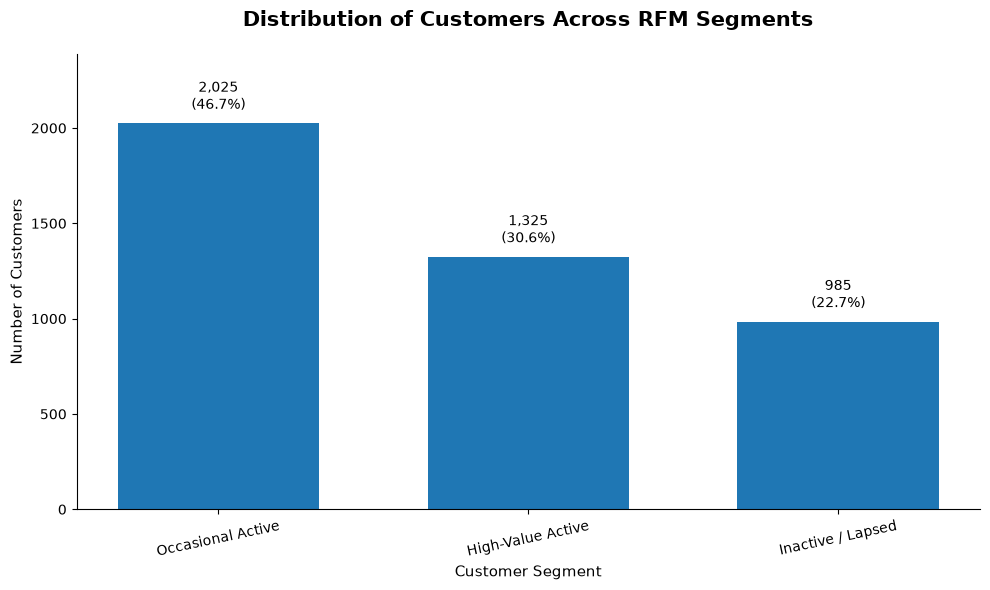

In [9]:
# Section 6.4 – Improved customer segment distribution chart

import matplotlib.pyplot as plt

cluster_distribution = (
    rfm_profile_data["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_labels = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

display_distribution = cluster_distribution.rename(
    index=cluster_labels
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    display_distribution.index,
    display_distribution.values,
    width=0.65
)

ax.set_title(
    "Distribution of Customers Across RFM Segments",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Customer Segment", fontsize=11)
ax.set_ylabel("Number of Customers", fontsize=11)

ax.set_ylim(0, display_distribution.max() * 1.18)

ax.tick_params(axis="x", rotation=12)

for bar, count in zip(bars, display_distribution.values):
    percentage = count / len(rfm_profile_data) * 100

    ax.annotate(
        f"{count:,}\n({percentage:.1f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Section 6.5 – RFM median profile comparison

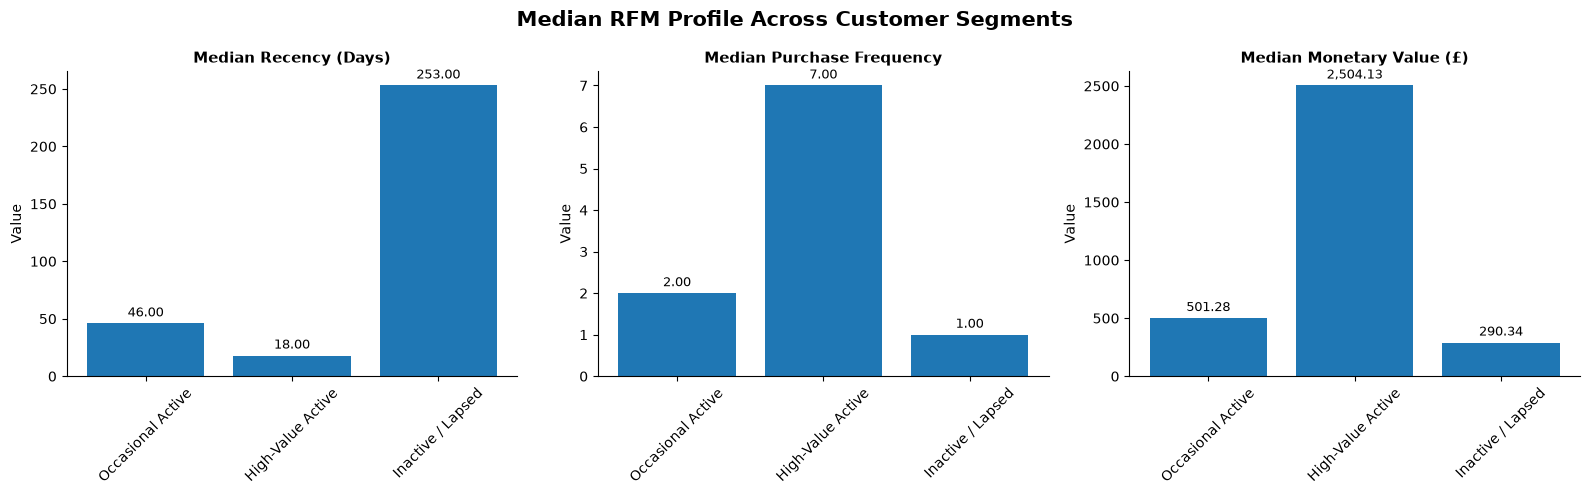

In [10]:
# Section 6.5 – RFM median profile comparison

import matplotlib.pyplot as plt

rfm_medians = (
    rfm_profile_data
    .groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .median()
)

segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

rfm_medians.index = rfm_medians.index.map(segment_names)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables = [
    ("Recency", "Median Recency (Days)"),
    ("Frequency", "Median Purchase Frequency"),
    ("Monetary", "Median Monetary Value (£)")
]

for ax, (variable, title) in zip(axes, variables):

    values = rfm_medians[variable]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Value")

    for bar, value in zip(bars, values.values):
        ax.annotate(
            f"{value:,.2f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Median RFM Profile Across Customer Segments",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Section 6.6 – Extended behavioural profile comparison

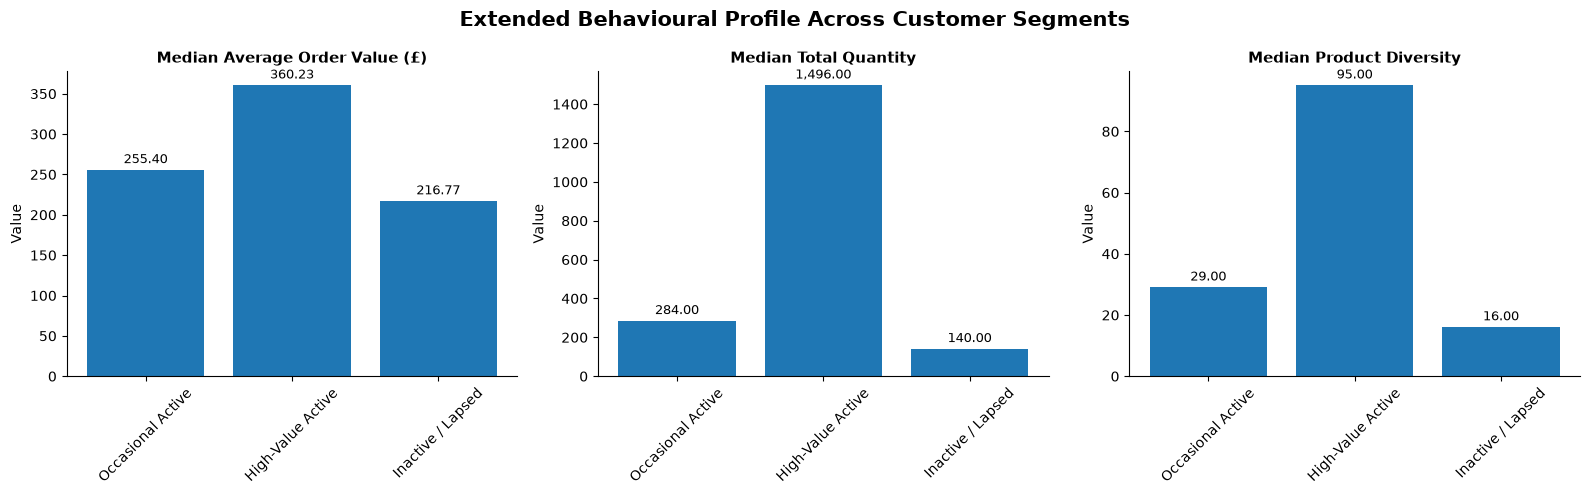

In [11]:
# Section 6.6 – Extended behavioural profile comparison

extended_medians = (
    rfm_profile_data
    .groupby("Cluster")[
        ["AverageOrderValue", "TotalQuantity", "ProductDiversity"]
    ]
    .median()
)

segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

extended_medians.index = extended_medians.index.map(segment_names)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables = [
    ("AverageOrderValue", "Median Average Order Value (£)"),
    ("TotalQuantity", "Median Total Quantity"),
    ("ProductDiversity", "Median Product Diversity")
]

for ax, (variable, title) in zip(axes, variables):

    values = extended_medians[variable]

    bars = ax.bar(
        values.index,
        values.values
    )

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Value")

    for bar, value in zip(bars, values.values):
        ax.annotate(
            f"{value:,.2f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Extended Behavioural Profile Across Customer Segments",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Section 6.7 – Verify availability of the original transaction dataset

In [12]:
# Section 6.7 – Verify availability of the original transaction dataset

RAW_DIR = PROJECT_ROOT / "data" / "raw"

raw_file = RAW_DIR / "Online Retail.xlsx"

print("RAW DATA VERIFICATION")
print("--------------------------------")
print("Raw dataset path:", raw_file)
print("File available:", raw_file.exists())

if raw_file.exists():
    print("File size (MB):", round(raw_file.stat().st_size / (1024 * 1024), 2))

RAW DATA VERIFICATION
--------------------------------
Raw dataset path: c:\Users\yadav\OneDrive\Desktop\Online_Retail_Customer_Segmentation\data\raw\Online Retail.xlsx
File available: True
File size (MB): 22.62


### Section 6.8 – Inspect country information in the raw transaction dataset

In [13]:
# Section 6.8 – Inspect country information in the raw transaction dataset

raw_df = pd.read_excel(
    raw_file,
    usecols=["InvoiceNo", "StockCode", "Quantity", "UnitPrice",
             "CustomerID", "Country"]
)

print("RAW TRANSACTION DATA")
print("--------------------------------")

print("Shape:", raw_df.shape)

print("\nMissing values:")
display(raw_df[["CustomerID", "Country"]].isnull().sum())

print("\nNumber of unique countries:",
      raw_df["Country"].nunique())

print("\nTop 15 countries by transaction records:")
display(
    raw_df["Country"]
    .value_counts()
    .head(15)
    .to_frame("Transaction_Records")
)

print("\nSample records:")
display(raw_df.head())

RAW TRANSACTION DATA
--------------------------------
Shape: (541909, 6)

Missing values:


CustomerID    135080
Country            0
dtype: int64


Number of unique countries: 38

Top 15 countries by transaction records:


,Transaction_Records
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519



Sample records:


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,Country
0,536365,85123A,6,2.55,17850.0,United Kingdom
1,536365,71053,6,3.39,17850.0,United Kingdom
2,536365,84406B,8,2.75,17850.0,United Kingdom
3,536365,84029G,6,3.39,17850.0,United Kingdom
4,536365,84029E,6,3.39,17850.0,United Kingdom


### Section 6.9 – Create customer-level country mapping

In [14]:
# Section 6.9 – Create customer-level country mapping

# Reload the complete dataset to preserve the original
# duplicate-removal and preprocessing logic
country_df = pd.read_excel(raw_file)

initial_rows = len(country_df)

# Step 1: Remove exact duplicate records
country_df = country_df.drop_duplicates()

# Step 2: Exclude cancellation invoices
country_df = country_df[
    ~country_df["InvoiceNo"].astype(str).str.startswith("C")
]

# Step 3: Retain identified customers
country_df = country_df[
    country_df["CustomerID"].notna()
]

# Step 4: Retain positive transaction quantities and prices
country_df = country_df[
    (country_df["Quantity"] > 0) &
    (country_df["UnitPrice"] > 0)
]

# Step 5: Exclude non-merchandise stock codes
excluded_codes = ["POST", "DOT", "M"]

country_df = country_df[
    ~country_df["StockCode"].astype(str).isin(excluded_codes)
]

print("COUNTRY PROFILING DATA PREPARATION")
print("--------------------------------")
print("Initial transaction rows:", initial_rows)
print("Rows after cleaning:", len(country_df))
print("Unique customers:", country_df["CustomerID"].nunique())

# Step 6: Count distinct countries associated with each customer
customer_country_counts = (
    country_df.groupby("CustomerID")["Country"]
    .nunique()
)

print("\nCUSTOMER-COUNTRY ASSOCIATION")
print("--------------------------------")

print("Customers associated with exactly one country:",
      (customer_country_counts == 1).sum())

print("Customers associated with multiple countries:",
      (customer_country_counts > 1).sum())

print("Customers without country information:",
      (customer_country_counts == 0).sum())

# Inspect customers associated with multiple countries
multi_country_customers = customer_country_counts[
    customer_country_counts > 1
]

if len(multi_country_customers) > 0:
    print("\nCustomers associated with multiple countries:")
    display(
        country_df[
            country_df["CustomerID"].isin(
                multi_country_customers.index
            )
        ][["CustomerID", "Country"]]
        .drop_duplicates()
        .sort_values("CustomerID")
        .head(20)
    )

COUNTRY PROFILING DATA PREPARATION
--------------------------------
Initial transaction rows: 541909
Rows after cleaning: 391298
Unique customers: 4335

CUSTOMER-COUNTRY ASSOCIATION
--------------------------------
Customers associated with exactly one country: 4327
Customers associated with multiple countries: 8
Customers without country information: 0

Customers associated with multiple countries:


,CustomerID,Country
34293,12370.0,Austria
29732,12370.0,Cyprus
383089,12394.0,Denmark
177881,12394.0,Belgium
34461,12417.0,Belgium
171221,12417.0,Spain
239276,12422.0,Switzerland
63100,12422.0,Australia
168399,12429.0,Austria
20017,12429.0,Denmark


In [15]:
# Section 6.9.1 – Examine multi-country customers

multi_country_details = (
    country_df[
        country_df["CustomerID"].isin(
            multi_country_customers.index
        )
    ]
    .groupby(["CustomerID", "Country"])
    .size()
    .reset_index(name="Transaction_Count")
    .sort_values(
        ["CustomerID", "Transaction_Count"],
        ascending=[True, False]
    )
)

display(multi_country_details)

# Check whether any customer has a tie in transaction counts
max_counts = (
    multi_country_details
    .groupby("CustomerID")["Transaction_Count"]
    .transform("max")
)

top_countries = multi_country_details[
    multi_country_details["Transaction_Count"] == max_counts
]

tie_counts = top_countries.groupby("CustomerID").size()

print("\nNumber of customers with tied leading countries:",
      (tie_counts > 1).sum())

,CustomerID,Country,Transaction_Count
1,12370.0,Cyprus,158
0,12370.0,Austria,7
2,12394.0,Belgium,20
3,12394.0,Denmark,5
4,12417.0,Belgium,161
5,12417.0,Spain,22
6,12422.0,Australia,21
7,12422.0,Switzerland,17
9,12429.0,Denmark,74
8,12429.0,Austria,20



Number of customers with tied leading countries: 0


In [16]:
# Section 6.9.2 – Assign one primary country to each customer

# Count qualifying transaction records by customer and country
customer_country_mapping = (
    country_df
    .groupby(["CustomerID", "Country"])
    .size()
    .reset_index(name="Transaction_Count")
)

# Sort so that the country with the highest transaction count comes first
customer_country_mapping = customer_country_mapping.sort_values(
    ["CustomerID", "Transaction_Count", "Country"],
    ascending=[True, False, True]
)

# Assign the most frequently recorded country to each customer
customer_country_mapping = (
    customer_country_mapping
    .drop_duplicates(subset="CustomerID", keep="first")
    [["CustomerID", "Country"]]
)

# Merge country information with customer-level features and cluster labels
customer_country_profile = customer_features.merge(
    customer_country_mapping,
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

customer_country_profile["Cluster"] = rfm_kmeans_labels

# Verify mapping
print("CUSTOMER-LEVEL COUNTRY MAPPING")
print("--------------------------------")

print("Total customers:", len(customer_country_profile))
print("Unique customer IDs:",
      customer_country_profile["CustomerID"].nunique())

print("Missing country assignments:",
      customer_country_profile["Country"].isna().sum())

print("Duplicate customer IDs:",
      customer_country_profile["CustomerID"].duplicated().sum())

print("\nNumber of countries:",
      customer_country_profile["Country"].nunique())

print("\nTop 15 countries by customer count:")

display(
    customer_country_profile["Country"]
    .value_counts()
    .head(15)
    .rename_axis("Country")
    .reset_index(name="Customer_Count")
)

CUSTOMER-LEVEL COUNTRY MAPPING
--------------------------------
Total customers: 4335
Unique customer IDs: 4335
Missing country assignments: 0
Duplicate customer IDs: 0

Number of countries: 37

Top 15 countries by customer count:


,Country,Customer_Count
0,United Kingdom,3917
1,Germany,94
2,France,87
3,Spain,29
4,Belgium,24
5,Switzerland,20
6,Portugal,19
7,Italy,14
8,Finland,12
9,Norway,10


In [17]:
# Section 6.9.3 – Country-wise customer segment distribution

# Customer counts by country and cluster
country_cluster_counts = pd.crosstab(
    customer_country_profile["Country"],
    customer_country_profile["Cluster"]
)

# Rename cluster columns
country_cluster_counts = country_cluster_counts.rename(
    columns={
        0: "Occasional Active",
        1: "High-Value Active",
        2: "Inactive / Lapsed"
    }
)

# Calculate percentages within each country
country_cluster_percentages = (
    country_cluster_counts
    .div(country_cluster_counts.sum(axis=1), axis=0)
    * 100
)

# Sort countries by total customer count
country_cluster_counts["Total Customers"] = (
    country_cluster_counts.sum(axis=1)
)

country_cluster_counts = country_cluster_counts.sort_values(
    "Total Customers",
    ascending=False
)

country_cluster_percentages = country_cluster_percentages.reindex(
    country_cluster_counts.index
)

print("COUNTRY-WISE CUSTOMER SEGMENT COUNTS")
print("--------------------------------")

display(country_cluster_counts.head(15))

print("\nCOUNTRY-WISE CUSTOMER SEGMENT DISTRIBUTION (%)")
print("--------------------------------")

display(country_cluster_percentages.head(15).round(2))

COUNTRY-WISE CUSTOMER SEGMENT COUNTS
--------------------------------


Cluster,Occasional Active,High-Value Active,Inactive / Lapsed,Total Customers
Country,,,,
United Kingdom,1832,1190,895,3917
Germany,43,34,17,94
France,38,31,18,87
Spain,16,8,5,29
Belgium,7,12,5,24
Switzerland,10,6,4,20
Portugal,8,5,6,19
Italy,7,3,4,14
Finland,7,4,1,12



COUNTRY-WISE CUSTOMER SEGMENT DISTRIBUTION (%)
--------------------------------


Cluster,Occasional Active,High-Value Active,Inactive / Lapsed
Country,,,
United Kingdom,46.77,30.38,22.85
Germany,45.74,36.17,18.09
France,43.68,35.63,20.69
Spain,55.17,27.59,17.24
Belgium,29.17,50.00,20.83
Switzerland,50.00,30.00,20.00
Portugal,42.11,26.32,31.58
Italy,50.00,21.43,28.57
Finland,58.33,33.33,8.33


### Section 6.10 – Consolidated customer segment profile

In [18]:
# Section 6.10 – Consolidated customer segment profile

segment_profile = (
    rfm_profile_data
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Median_AOV=("AverageOrderValue", "median"),
        Median_Total_Quantity=("TotalQuantity", "median"),
        Median_Product_Diversity=("ProductDiversity", "median")
    )
)

# Calculate customer percentages
segment_profile["Customer_Percentage"] = (
    segment_profile["Customer_Count"]
    / len(rfm_profile_data)
    * 100
)

# Assign meaningful segment names
segment_profile.index = segment_profile.index.map({
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
})

# Arrange columns
segment_profile = segment_profile[
    [
        "Customer_Count",
        "Customer_Percentage",
        "Median_Recency",
        "Median_Frequency",
        "Median_Monetary",
        "Median_AOV",
        "Median_Total_Quantity",
        "Median_Product_Diversity"
    ]
]

print("CONSOLIDATED CUSTOMER SEGMENT PROFILE")
print("--------------------------------")

display(segment_profile.round(2))

CONSOLIDATED CUSTOMER SEGMENT PROFILE
--------------------------------


,Customer_Count,Customer_Percentage,Median_Recency,Median_Frequency,Median_Monetary,Median_AOV,Median_Total_Quantity,Median_Product_Diversity
Cluster,,,,,,,,
Occasional Active,2025,46.71,46.0,2.0,501.28,255.40,284.0,29.0
High-Value Active,1325,30.57,18.0,7.0,2504.13,360.23,1496.0,95.0
Inactive / Lapsed,985,22.72,253.0,1.0,290.34,216.76,140.0,16.0


### 6.11 Business Recommendations

Based on the identified customer segments, differentiated customer engagement strategies are recommended.

**1. Occasional Active Customers**

As the largest customer segment, these customers represent an opportunity to strengthen repeat purchasing behaviour. The business could introduce personalised product recommendations, targeted cross-selling campaigns and incentives for repeat purchases. The objective would be to increase purchase frequency and product engagement.

**2. High-Value Active Customers**

These customers demonstrate the strongest purchasing engagement and monetary contribution. Retention should therefore be a priority. Potential interventions include loyalty programmes, personalised offers, exclusive product access and priority customer support. These initiatives could help maintain customer engagement and strengthen long-term relationships.

**3. Inactive / Lapsed Customers**

Customers in this segment have not purchased for a considerable period and generally exhibit low historical purchasing frequency. Targeted reactivation campaigns, personalised communication and carefully designed win-back incentives could be tested to encourage renewed purchasing activity.

**Implementation and measurement**

The proposed interventions should be evaluated using measurable indicators such as repeat purchase rate, customer retention rate, reactivation rate, purchase frequency and campaign conversion rate. Controlled campaign experiments could help establish whether these interventions produce measurable improvements.

These recommendations are based on observed historical purchasing patterns. Their effectiveness has not been tested within the present clustering analysis.

### Section 6.12 – Final model evaluation summary

In [19]:
# Section 6.12 – Final model evaluation summary

# Identify the selected model from our candidate comparison
selected_model_name = "RFM | K-Means | K=3"

# Extract selected model metrics
selected_model_metrics = final_model_comparison[
    final_model_comparison["Model"] == selected_model_name
].copy()

# Create final evaluation summary
final_evaluation_summary = final_model_comparison[
    [
        "Model",
        "Number_of_Clusters",
        "Silhouette_Score",
        "Davies_Bouldin_Index",
        "Calinski_Harabasz_Index"
    ]
].copy()

# Add selection status
final_evaluation_summary["Selection_Status"] = (
    final_evaluation_summary["Model"]
    .apply(
        lambda x: "Selected Model"
        if x == selected_model_name
        else "Alternative Model"
    )
)

print("FINAL MODEL EVALUATION SUMMARY")
print("--------------------------------")

display(final_evaluation_summary.round(4))

print("\nSELECTED MODEL")
print("--------------------------------")

display(selected_model_metrics.round(4))

FINAL MODEL EVALUATION SUMMARY
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index,Selection_Status
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206,Selected Model
1,RFM | Hierarchical | K=2,2,0.3965,0.8371,3276.0686,Alternative Model
2,RFM | Hierarchical | K=3,3,0.3956,0.8669,4151.0791,Alternative Model
3,Extended | K-Means | K=2,2,0.3511,1.0616,3116.7941,Alternative Model
4,Reduced Extended | K-Means | K=2,2,0.3360,1.1176,2802.5822,Alternative Model
5,Extended | Hierarchical | K=2,2,0.3237,1.0306,2510.9298,Alternative Model



SELECTED MODEL
--------------------------------


,Model,Number_of_Clusters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,RFM | K-Means | K=3,3,0.4151,0.8269,4378.5206


### Section 6.13 – Final customer segment summary


In [20]:
# Section 6.13 – Final customer segment summary

# Calculate the final customer segment profiles
final_segment_summary = (
    rfm_profile_data
    .groupby("Cluster")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Median_AOV=("AverageOrderValue", "median"),
        Median_Total_Quantity=("TotalQuantity", "median"),
        Median_Product_Diversity=("ProductDiversity", "median")
    )
)

# Calculate customer percentages
final_segment_summary["Customer_Percentage"] = (
    final_segment_summary["Customer_Count"]
    / len(rfm_profile_data)
    * 100
)

# Assign descriptive segment names
segment_names = {
    0: "Occasional Active",
    1: "High-Value Active",
    2: "Inactive / Lapsed"
}

final_segment_summary.index = (
    final_segment_summary.index.map(segment_names)
)

# Add commercial interpretations
segment_interpretations = {
    "Occasional Active":
        "Relatively recent but infrequent purchasers with moderate spending and product engagement.",

    "High-Value Active":
        "Highly engaged customers with frequent purchases, higher spending and greater product diversity.",

    "Inactive / Lapsed":
        "Customers with long purchase inactivity, low frequency and relatively low historical spending."
}

final_segment_summary["Commercial_Interpretation"] = (
    final_segment_summary.index.map(segment_interpretations)
)

# Arrange columns
final_segment_summary = final_segment_summary[
    [
        "Customer_Count",
        "Customer_Percentage",
        "Median_Recency",
        "Median_Frequency",
        "Median_Monetary",
        "Median_AOV",
        "Median_Total_Quantity",
        "Median_Product_Diversity",
        "Commercial_Interpretation"
    ]
]

print("FINAL CUSTOMER SEGMENT SUMMARY")
print("--------------------------------")

display(final_segment_summary.round(2))

# Validate customer coverage
print("\nVALIDATION")
print("--------------------------------")
print("Total customers:",
      final_segment_summary["Customer_Count"].sum())

print("Total segment percentage:",
      round(final_segment_summary["Customer_Percentage"].sum(), 2))

FINAL CUSTOMER SEGMENT SUMMARY
--------------------------------


,Customer_Count,Customer_Percentage,Median_Recency,Median_Frequency,Median_Monetary,Median_AOV,Median_Total_Quantity,Median_Product_Diversity,Commercial_Interpretation
Cluster,,,,,,,,,
Occasional Active,2025,46.71,46.0,2.0,501.28,255.40,284.0,29.0,Relatively recent but infrequent purchasers wi...
High-Value Active,1325,30.57,18.0,7.0,2504.13,360.23,1496.0,95.0,Highly engaged customers with frequent purchas...
Inactive / Lapsed,985,22.72,253.0,1.0,290.34,216.76,140.0,16.0,"Customers with long purchase inactivity, low f..."



VALIDATION
--------------------------------
Total customers: 4335
Total segment percentage: 100.0


### 6.14 Limitations and Responsible Machine Learning

The customer segmentation analysis provides useful insights into purchasing behaviour, but several limitations should be considered when interpreting and applying the results.

**1. Dataset representativeness**

The analysis uses historical transaction data from a single online retailer covering 2010–2011. Consequently, the identified customer segments may not represent customers of other retailers, industries or contemporary online retail environments.

**2. Geographical imbalance**

The United Kingdom accounts for approximately 90.36% of the customer population. Although geographical profiling was conducted, the relatively small customer populations in several other countries limit the reliability of cross-country comparisons.

**3. Feature selection**

The clustering models use RFM and selected extended purchasing characteristics. Other dimensions, such as customer demographics, preferences, marketing interactions and customer satisfaction, are not available in the analytical dataset. Therefore, the identified segments represent purchasing behaviour rather than a complete understanding of customer characteristics.

**4. Influence of extreme observations**

Customer spending and purchasing quantities exhibit substantial skewness. Although transformations, scaling comparisons and outlier sensitivity analysis were performed, distance-based clustering can still be influenced by extreme observations.

**5. Interpretation of clusters**

K-Means identifies mathematical groupings based on feature similarity. Labels such as High-Value Active, Occasional Active and Inactive/Lapsed are analytical interpretations of the resulting profiles, rather than predefined or objectively correct customer categories.

**6. Historical and temporal limitations**

The segmentation reflects purchasing activity during the observed historical period. Customer behaviour may change over time, and the analysis does not predict future purchases, customer churn or transitions between segments.

**7. Responsible use and privacy**

Customer identifiers were used for aggregation and analytical purposes rather than as behavioural predictors. Although the dataset is deidentified, customer-level information should still be handled responsibly, with appropriate access controls and data protection practices.

The resulting segments should support business decision-making rather than replace human judgement. Any customer engagement strategy based on these segments should be evaluated before implementation. The clustering analysis identifies behavioural associations and does not establish causal relationships.

### 6.11 Phase 6 Conclusion

The customer segmentation analysis demonstrates that unsupervised machine learning can identify meaningful groups of customers based on their historical purchasing behaviour.

Among the evaluated candidate models, K-Means clustering using the RFM feature set with three clusters emerged as the preferred model. It achieved a Silhouette Score of 0.4151, a Davies-Bouldin Index of 0.8269 and a Calinski-Harabasz Index of 4,378.52.

The model identified three customer segments comprising Occasional Active Customers (46.71%), High-Value Active Customers (30.57%) and Inactive/Lapsed Customers (22.72%).

Extended behavioural profiling revealed that High-Value Active Customers demonstrated the strongest purchasing engagement, with higher purchase frequency, monetary contribution, average order value, cumulative purchase quantity and product diversity. Occasional Active Customers displayed moderate engagement, while Inactive/Lapsed Customers exhibited substantially longer purchase inactivity and lower purchasing activity.

The comparison between RFM and extended feature sets indicated that incorporating additional behavioural variables did not improve the internal clustering evaluation metrics in the experiments conducted. However, these variables contributed useful supplementary information for interpreting the resulting customer segments.

The comparison between K-Means and Agglomerative Hierarchical Clustering also favoured the three-cluster RFM K-Means solution in terms of the evaluated internal metrics and the interpretability of its customer profiles.

Overall, the findings demonstrate the potential of customer-level behavioural segmentation to support differentiated customer engagement, retention and reactivation strategies. However, the identified segments reflect historical purchasing patterns and should be treated as analytical groupings rather than predictions of future customer behaviour.

The analysis provides a foundation for more targeted retail decision-making, subject to further validation of the proposed business interventions.